# Step 5: Random vs domain-grouped split. How much does a random split inflate the scores?

Most published results on these datasets use a **random** train/test split. Then pages of the
*same website* appear in both training and test, and the model can memorise websites instead of
learning what makes a URL malicious. Our project uses a split **grouped by registered domain**
(Step 1), so every test URL comes from a website the model has never seen.

Here we train **the same recipes** on a random split and compare:

* same cleaned data (856,600 URLs) and the same 43 features (`feature_list.json` order);
* the 42 lexical features are split-independent, so they are reused from the Step 1 parquet files;
* only `tld_malicious_rate` depends on the labels. It is **recomputed for the random split exactly
  like Step 1**: `UrlFeatureExtractor` fitted on random-train only, out-of-fold values (5 folds
  grouped by domain) for the training rows;
* same recipes as Step 2: tuned XGBoost, the deployable RF (`rf_small_6`), and the deployed Soft
  Voting (RF + tuned XGBoost + LightGBM), each trained **without the documented noisy rows**;
* thresholds: 0.5, and the FPR ≤ 1% threshold chosen on the respective validation set.

**Fair comparison.** In Step 2 the grouped **test** set was used only once, for the deployed Soft
Voting model and the reference RF. So the deployed recipe is compared **test vs test**, while
XGBoost and RF are compared **validation vs validation**. The grouped-split numbers are read from
the cached Step 2 predictions, cross-checked against `reports/metrics/`. No new model is scored on
the grouped test set.

In [1]:
import sys, json, time, gc, warnings
from pathlib import Path
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib, psutil
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from src import config as C, data as D, features as F, viz as V, modeling as M
V.set_style(); warnings.filterwarnings("ignore", message=".*valid feature names.*")
pd.set_option("display.width", 220)
RS = C.RANDOM_STATE
FEATS = M.feature_list()
LEX = [f for f in FEATS if f != "tld_malicious_rate"]
CACHE = M.CACHE / "split_random"; CACHE.mkdir(parents=True, exist_ok=True)

meta_cols = ["label", "type", "source", "registered_domain", "url_normalized"]
full = pd.concat([pd.read_parquet(C.PROCESSED / f"{s}.parquet", columns=LEX + meta_cols).assign(grouped_split=s)
                  for s in ["train", "val", "test"]], ignore_index=True)
print(f"{len(full):,} URLs, {len(LEX)} lexical features reused from Step 1 (+ tld_malicious_rate recomputed)")

# Memory guard (same idea as Step 2): the models here are small, the data dominates
need_mb = full.memory_usage(deep=True).sum() / 1e6 * 3 + 1500     # data copies + models, generous
free_mb = psutil.virtual_memory().available / 1e6
print(f"free RAM {free_mb:,.0f} MB; estimated need {need_mb:,.0f} MB; budget (free - 1 GB) {free_mb - 1000:,.0f} MB")
assert need_mb < free_mb - 1000, "not enough free RAM, close other programs"

856,600 URLs, 42 lexical features reused from Step 1 (+ tld_malicious_rate recomputed)
free RAM 4,446 MB; estimated need 2,351 MB; budget (free - 1 GB) 3,446 MB


## 1. Random stratified split (70/15/15, `random_state=42`)

In [2]:
strat = full["source"] + "|" + full["type"]
idx = np.arange(len(full))
i_tr, i_rest = train_test_split(idx, test_size=0.30, stratify=strat, random_state=RS)
i_va, i_te = train_test_split(i_rest, test_size=0.50, stratify=strat.iloc[i_rest], random_state=RS)
rsplit = pd.Series("train", index=full.index); rsplit.iloc[i_va] = "val"; rsplit.iloc[i_te] = "test"
full["random_split"] = rsplit
sizes = full["random_split"].value_counts().reindex(["train", "val", "test"])
display(pd.DataFrame({"rows": sizes, "%": (100 * sizes / len(full)).round(2),
                      "malicious %": (100 * full.groupby("random_split")["label"].mean()).reindex(sizes.index).round(2)}))

train_domains = set(full.loc[full.random_split == "train", "registered_domain"])
leak = {s: full.loc[full.random_split == s, "registered_domain"].isin(train_domains).mean() for s in ["val", "test"]}
g_train_domains = set(full.loc[full.grouped_split == "train", "registered_domain"])
g_leak = full.loc[full.grouped_split == "test", "registered_domain"].isin(g_train_domains).mean()
print(f"random split : {100*leak['test']:.1f}% of TEST URLs (val: {100*leak['val']:.1f}%) have a registered domain that is also in TRAIN")
print(f"grouped split: {100*g_leak:.1f}% of test URLs share a domain with train (by construction)")
print("Step 1 measured 65.8% for a plain (non-stratified) random 70/15/15 split")

,rows,%,malicious %
random_split,,,
train,599620,70.0,35.32
val,128490,15.0,35.32
test,128490,15.0,35.32


random split : 66.0% of TEST URLs (val: 66.0%) have a registered domain that is also in TRAIN
grouped split: 0.0% of test URLs share a domain with train (by construction)
Step 1 measured 65.8% for a plain (non-stratified) random 70/15/15 split


**Insight:** The random stratified split gives exactly 70/15/15 (599,620 / 128,490 / 128,490 rows) with an identical malicious share of 35.32% in each part. However, **66.0% of the random-test URLs come from a registered domain that is also in random-train** (66.0% for validation too, close to the 65.8% Step 1 measured). In the grouped split this share is 0% by construction. So two thirds of a random test set are pages of websites the model has already seen.

## 2. `tld_malicious_rate` recomputed for the random split (fit on random-train only, out-of-fold for train rows)

In [3]:
rtr = (full.random_split == "train").to_numpy()
fx_r = F.UrlFeatureExtractor(m=C.TLD_SMOOTHING_M, n_splits=5, random_state=RS)
t = time.perf_counter()
fx_r.fit(full.loc[rtr, "url_normalized"], full.loc[rtr, "label"], already_normalized=True)
full["tld_malicious_rate"] = np.nan
full.loc[rtr, "tld_malicious_rate"] = fx_r.oof_tld_feature(full.loc[rtr, "url_normalized"], full.loc[rtr, "label"],
                                                            groups=full.loc[rtr, "registered_domain"], already_normalized=True)
full.loc[~rtr, "tld_malicious_rate"] = fx_r.tld_feature(full.loc[~rtr, "url_normalized"], already_normalized=True)
assert full["tld_malicious_rate"].notna().all()
print(f"TLD encoding: prior {fx_r.prior_:.4f}, {len(fx_r.tld_rates_):,} TLDs, {time.perf_counter() - t:.1f}s")

TLD encoding: prior 0.3532, 1,392 TLDs, 7.5s


## 3. Train the Step 2 recipes on random-train (noisy rows removed, as in Step 2)

In [4]:
def noise_mask(df):
    kp = (df.source == "kaggle_malicious_phish") & (df.type == "phishing")
    iw = kp & df.registered_domain.isin(["ietf.org", "wikipedia.org"])
    ws = (df.label == 0) & df.url_normalized.str.lower().str.contains("webscr", regex=False)
    return (iw | ws).to_numpy()

noisy = noise_mask(full)
fit_mask = rtr & ~noisy
print(f"random-train rows {rtr.sum():,}; noisy rows removed {(rtr & noisy).sum():,}; fitted on {fit_mask.sum():,}")

xgb_best = joblib.load(M.CACHE / "xgboost_search.joblib")["best_params"]
rf_params = json.loads((M.CACHE / "rf_small_6.json").read_text())["note"]
rf_params = {**joblib.load(M.CACHE / "rf_search.joblib")["best_params"], **json.loads(rf_params)}
rf_params["min_samples_leaf"] = max(rf_params["min_samples_leaf"], 1)
RECIPES = {
    "XGBoost (tuned)": lambda: XGBClassifier(tree_method="hist", random_state=RS, eval_metric="logloss", n_jobs=-1, **xgb_best),
    "RF small_6": lambda: RandomForestClassifier(**rf_params, n_jobs=-1, random_state=RS),
    "LightGBM": lambda: LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=63, n_jobs=-1, random_state=RS, verbose=-1),
}
print("RF params:", rf_params); print("XGB params:", xgb_best)

X, y = full[FEATS], full["label"].to_numpy()
rva, rte = (full.random_split == "val").to_numpy(), (full.random_split == "test").to_numpy()
fit_times = {}
times_path = CACHE / "fit_times.json"
if times_path.exists():
    fit_times = json.loads(times_path.read_text())
for name, make in RECIPES.items():
    key = name.replace(" ", "_").replace("(", "").replace(")", "")
    pv, pt = CACHE / f"{key}__val.npy", CACHE / f"{key}__test.npy"
    if pv.exists() and pt.exists():
        continue
    m = make(); t = time.perf_counter(); m.fit(X[fit_mask], y[fit_mask]); fit_times[name] = round(time.perf_counter() - t, 1)
    np.save(pv, m.predict_proba(X[rva])[:, 1]); np.save(pt, m.predict_proba(X[rte])[:, 1])
    del m; gc.collect()
times_path.write_text(json.dumps(fit_times, indent=2))
P = {}
for name in RECIPES:
    key = name.replace(" ", "_").replace("(", "").replace(")", "")
    P[name] = {"val": np.load(CACHE / f"{key}__val.npy"), "test": np.load(CACHE / f"{key}__test.npy")}
P["Soft Voting (deployed recipe)"] = {s: np.mean([P[n][s] for n in ["RF small_6", "XGBoost (tuned)", "LightGBM"]], axis=0)
                                      for s in ["val", "test"]}
print("fit times (s, random-train):", fit_times)

random-train rows 599,620; noisy rows removed 6,651; fitted on 592,969
RF params: {'n_estimators': 50, 'min_samples_split': 2, 'min_samples_leaf': 16, 'max_samples': 0.8, 'max_features': 0.3, 'max_depth': 15, 'class_weight': 'balanced'}
XGB params: {'subsample': 0.8, 'reg_lambda': 5, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 12, 'learning_rate': 0.05, 'colsample_bytree': 0.7}
fit times (s, random-train): {'XGBoost (tuned)': 7.2, 'RF small_6': 8.4, 'LightGBM': 5.7}


## 4. Grouped-split results (from Step 2, cached predictions cross-checked with `reports/metrics/`)

In [5]:
gval = pd.read_parquet(C.PROCESSED / "val.parquet", columns=["label"])["label"].to_numpy()
gtest = pd.read_parquet(C.PROCESSED / "test.parquet", columns=["label"])["label"].to_numpy()
cand = pd.read_csv(ROOT / "reports/metrics/candidates_threshold.csv").set_index("key")
test_csv = pd.read_csv(ROOT / "reports/metrics/test_metrics.csv", index_col=0)
G = {"XGBoost (tuned)": "xgboost_tuned_noiseclean", "RF small_6": "rf_small_6_noiseclean",
     "Soft Voting (deployed recipe)": "voting_tuned_noiseclean"}
G_thr = {n: float(cand.loc[k, "threshold"]) for n, k in G.items()}
for n, k in G.items():   # cross-check: recomputed F1 at the Step 2 threshold == reports/metrics value
    f1 = M.binary_metrics(gval, np.load(M.CACHE / f"{k}__val.npy"), G_thr[n])["f1"]
    assert abs(f1 - cand.loc[k, "f1@thr"]) < 1e-9, (n, f1, cand.loc[k, "f1@thr"])
gt = M.binary_metrics(gtest, np.load(M.CACHE / "voting_tuned_noiseclean__test.npy"), G_thr["Soft Voting (deployed recipe)"])
row = test_csv.loc[[i for i in test_csv.index if i.startswith("Soft Voting")][0]]
assert abs(gt["f1"] - row["f1"]) < 1e-9 and abs(gt["roc_auc"] - row["roc_auc"]) < 1e-9
print("grouped-split thresholds (Step 2):", G_thr)
print("cross-check OK: cached predictions reproduce reports/metrics/candidates_threshold.csv and test_metrics.csv")

grouped-split thresholds (Step 2): {'XGBoost (tuned)': 0.8, 'RF small_6': 0.84, 'Soft Voting (deployed recipe)': 0.8}
cross-check OK: cached predictions reproduce reports/metrics/candidates_threshold.csv and test_metrics.csv


## 5. Side-by-side comparison

In [6]:
rows = []
cols = ["accuracy", "precision", "recall", "f1", "roc_auc", "fpr"]
yr_va, yr_te = y[rva], y[rte]
for name in ["Soft Voting (deployed recipe)", "XGBoost (tuned)", "RF small_6"]:
    thr_r, _ = M.pick_threshold(yr_va, P[name]["val"])
    sets = [("random", "val", yr_va, P[name]["val"], thr_r), ("random", "test", yr_te, P[name]["test"], thr_r),
            ("grouped", "val", gval, np.load(M.CACHE / f"{G[name]}__val.npy"), G_thr[name])]
    if name.startswith("Soft Voting"):
        sets.append(("grouped", "test", gtest, np.load(M.CACHE / "voting_tuned_noiseclean__test.npy"), G_thr[name]))
    for split, ev, yy, pp, thr in sets:
        for tname, t in [("0.5", 0.5), ("FPR<=1% (chosen on val)", thr)]:
            m = M.binary_metrics(yy, pp, t)
            rows.append({"model": name, "split": split, "evaluated on": ev, "threshold rule": tname,
                         "threshold": t, **{c: m[c] for c in cols}})
comp = pd.DataFrame(rows)
comp.to_csv(ROOT / "reports/metrics/split_comparison.csv", index=False)
pd.set_option("display.max_rows", 40)
comp.round(4)

,model,split,evaluated on,threshold rule,threshold,accuracy,precision,recall,f1,roc_auc,fpr
0,Soft Voting (deployed recipe),random,val,0.5,0.50,0.8683,0.8762,0.7304,0.7967,0.9298,0.0563
1,Soft Voting (deployed recipe),random,val,FPR<=1% (chosen on val),0.76,0.8403,0.9710,0.5648,0.7142,0.9298,0.0092
2,Soft Voting (deployed recipe),random,test,0.5,0.50,0.8704,0.8769,0.7365,0.8006,0.9318,0.0565
3,Soft Voting (deployed recipe),random,test,FPR<=1% (chosen on val),0.76,0.8415,0.9698,0.5690,0.7172,0.9318,0.0097
4,Soft Voting (deployed recipe),grouped,val,0.5,0.50,0.8337,0.8092,0.6911,0.7455,0.8891,0.0887
5,Soft Voting (deployed recipe),grouped,val,FPR<=1% (chosen on val),0.80,0.8128,0.9647,0.4866,0.6469,0.8891,0.0097
6,Soft Voting (deployed recipe),grouped,test,0.5,0.50,0.8299,0.7918,0.6776,0.7303,0.8883,0.0917
7,Soft Voting (deployed recipe),grouped,test,FPR<=1% (chosen on val),0.80,0.8115,0.9657,0.4616,0.6246,0.8883,0.0084
8,XGBoost (tuned),random,val,0.5,0.50,0.8731,0.9012,0.7196,0.8002,0.9357,0.0431
9,XGBoost (tuned),random,val,FPR<=1% (chosen on val),0.74,0.8494,0.9716,0.5908,0.7348,0.9357,0.0094


**Insight:** Recomputing `tld_malicious_rate` on random-train gives prior 0.3532 and 1,392 TLDs. 6,651 noisy rows were removed, so each recipe was fitted on 592,969 rows: XGBoost 7.2 s, RF 8.4 s, LightGBM 5.7 s.

For every model and every threshold rule, the **random split scores higher**. For the deployed Soft Voting recipe on test:

* **at 0.5:** F1 0.8006 vs 0.7303 and ROC-AUC 0.9318 vs 0.8883;
* **at the FPR ≤ 1% threshold:** F1 0.7172 vs 0.6246 and recall 0.5690 vs 0.4616, with the false-positive rate held at about 1% in both (0.97% vs 0.84%).

The validation-vs-validation rows for XGBoost and RF show the same pattern. The grouped-split rows reproduce the Step 2 values exactly; the notebook asserts this against `reports/metrics/`.

,model,evaluated on,threshold rule,F1 random,F1 grouped,F1 inflation (pts),recall random,recall grouped,ROC-AUC random,ROC-AUC grouped
0,Soft Voting (deployed recipe),test,0.5,0.8006,0.7303,7.0347,0.7365,0.6776,0.9318,0.8883
1,Soft Voting (deployed recipe),test,FPR<=1% (chosen on val),0.7172,0.6246,9.2553,0.5690,0.4616,0.9318,0.8883
2,XGBoost (tuned),val,0.5,0.8002,0.7437,5.6485,0.7196,0.6720,0.9357,0.8930
3,XGBoost (tuned),val,FPR<=1% (chosen on val),0.7348,0.6542,8.0653,0.5908,0.4943,0.9357,0.8930
4,RF small_6,val,0.5,0.7882,0.7374,5.0845,0.7745,0.7343,0.9190,0.8741
5,RF small_6,val,FPR<=1% (chosen on val),0.6779,0.5502,12.7680,0.5214,0.3863,0.9190,0.8741


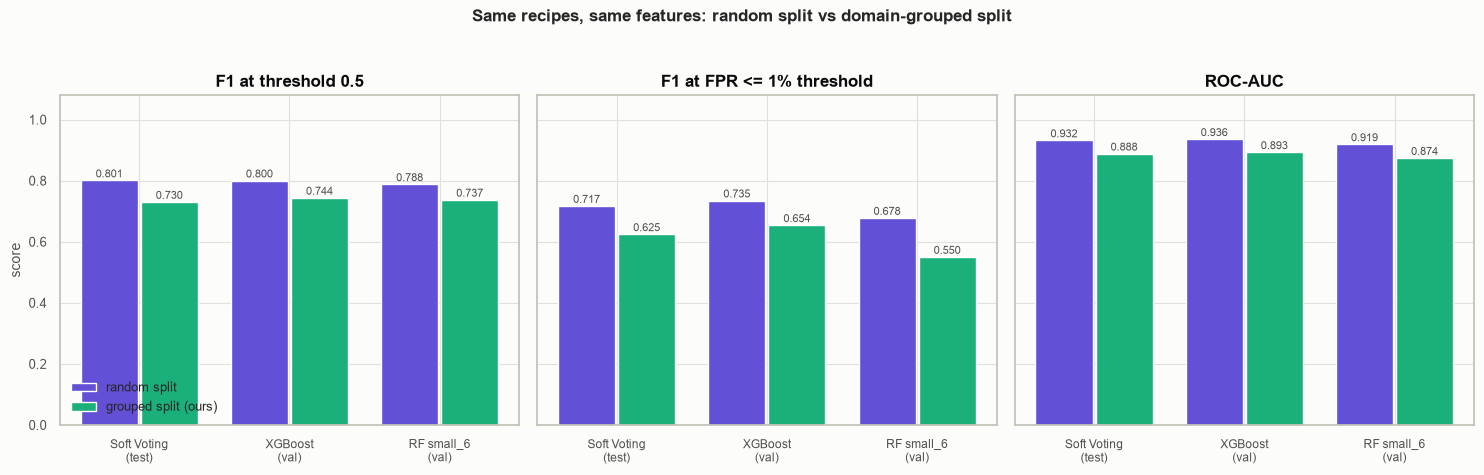

In [7]:
def pick(model, split, ev, rule):
    r = comp[(comp.model == model) & (comp.split == split) & (comp["evaluated on"] == ev) & (comp["threshold rule"] == rule)]
    return r.iloc[0]

summary = []
for name, ev in [("Soft Voting (deployed recipe)", "test"), ("XGBoost (tuned)", "val"), ("RF small_6", "val")]:
    for rule in ["0.5", "FPR<=1% (chosen on val)"]:
        r, g = pick(name, "random", ev, rule), pick(name, "grouped", ev, rule)
        summary.append({"model": name, "evaluated on": ev, "threshold rule": rule,
                        "F1 random": r.f1, "F1 grouped": g.f1, "F1 inflation (pts)": 100 * (r.f1 - g.f1),
                        "recall random": r.recall, "recall grouped": g.recall,
                        "ROC-AUC random": r.roc_auc, "ROC-AUC grouped": g.roc_auc})
summ = pd.DataFrame(summary)
display(summ.round(4))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
COL = {"random split": V.FAMILY_COLORS["single"], "grouped split (ours)": V.FAMILY_COLORS["bagging"]}
for ax, (metric, title) in zip(axes, [("F1@0.5", "F1 at threshold 0.5"), ("F1@thr", "F1 at FPR <= 1% threshold"), ("AUC", "ROC-AUC")]):
    labels, rv, gv = [], [], []
    for name, ev in [("Soft Voting (deployed recipe)", "test"), ("XGBoost (tuned)", "val"), ("RF small_6", "val")]:
        rule = "0.5" if metric == "F1@0.5" else "FPR<=1% (chosen on val)"
        col = "roc_auc" if metric == "AUC" else "f1"
        labels.append(f"{name.split(' (')[0]}\n({ev})")
        rv.append(pick(name, "random", ev, rule)[col]); gv.append(pick(name, "grouped", ev, rule)[col])
    x = np.arange(len(labels))
    b1 = ax.bar(x - 0.2, rv, 0.38, color=COL["random split"], label="random split")
    b2 = ax.bar(x + 0.2, gv, 0.38, color=COL["grouped split (ours)"], label="grouped split (ours)")
    for b, v in list(zip(b1, rv)) + list(zip(b2, gv)):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.3f}", ha="center", fontsize=8, color=V.INK_2)
    ax.set_xticks(x, labels, fontsize=8.5); ax.set_title(title); ax.set_ylim(0, 1.08)
axes[0].set_ylabel("score"); axes[0].legend(loc="lower left")
fig.suptitle("Same recipes, same features: random split vs domain-grouped split", fontsize=12, fontweight="bold", y=1.03)
fig.tight_layout(); V.savefig(fig, 25, "random_vs_grouped_split"); plt.show()

**Insight:** The figure compares the two splits.

* **F1 inflation from the random split:**
  * 5.1–7.0 points at threshold 0.5;
  * 8.1–12.8 points at the strict FPR ≤ 1% threshold.
* **ROC-AUC:** 0.919–0.937 (random) vs 0.874–0.893 (grouped).
* **Who benefits most:** the inflation is largest for the Random Forest at the strict threshold (+12.8 points, 0.6779 vs 0.5502). Deep trees memorise websites best, so they gain most when test websites were already seen in training.

The ranking of the recipes stays the same on both splits. The random split changes how good the models *look*, not which one is best.

## 6. Where does the inflation come from? Seen vs unseen domains inside the random test set

In [8]:
te_df = full.loc[rte, ["registered_domain", "label"]].copy()
te_df["p"] = P["Soft Voting (deployed recipe)"]["test"]
te_df["seen"] = te_df.registered_domain.isin(train_domains)
thr_r, _ = M.pick_threshold(yr_va, P["Soft Voting (deployed recipe)"]["val"])
seen_tab = pd.DataFrame({g: {**M.binary_metrics(d.label.to_numpy(), d.p.to_numpy(), thr_r), "URLs": len(d)}
                         for g, d in [("domain seen in random-train", te_df[te_df.seen]),
                                      ("domain NOT in random-train", te_df[~te_df.seen])]}).T
display(seen_tab[["URLs", "accuracy", "precision", "recall", "f1", "roc_auc", "fpr"]].round(4))

,URLs,accuracy,precision,recall,f1,roc_auc,fpr
domain seen in random-train,84846.0,0.8716,0.9836,0.6812,0.8049,0.9694,0.0072
domain NOT in random-train,43644.0,0.7829,0.8859,0.2702,0.4141,0.7921,0.0138


**Insight:** Inside the random test set, the deployed recipe (threshold 0.76, chosen on random-val) is nearly two different models:

* on the **84,846 URLs whose domain was seen in training**: F1 **0.805**, precision 0.984, ROC-AUC 0.969;
* on the **43,644 URLs from unseen domains**: F1 only **0.414**, recall 0.270, ROC-AUC 0.792.

So the random-split score is mostly a score for *recognising known websites*. The unseen-domain part behaves like our grouped evaluation, and like the 22% recall on never-seen OpenPhish domains in Step 2. This is the direct evidence that a random split overstates what a browser extension will achieve on new phishing sites.

## 7. Summary

**Insight:** * **Inflation:** with the same data, features and recipes, a random split reports **F1 0.80 instead of 0.73** at 0.5 for the deployed model, and **0.72 instead of 0.62** at the deployment threshold. That is 5–13 F1 points of inflation across the three recipes.
* **Cause:** two thirds of random-test URLs belong to websites already seen in training, and on those the model scores F1 0.80, while on unseen websites it scores 0.41.
* **Why our scores are lower than published ones:**
  1. We evaluate on unseen websites (this notebook).
  2. We removed the scheme/www/path shortcuts (Step 1: the scheme alone had ROC-AUC 0.788).
  3. We kept the label noise instead of cleaning it by hand.

Even the random split here stays far below the ~0.97 often reported, which is consistent with the shortcuts no longer being available. That last part is an interpretation; it was not measured here.